In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

In [2]:
df = pd.read_csv("train.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns)

Dataset Shape: (42000, 785)
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel780  pixel781  pixel782  pixel783  
0 

In [3]:
print("Missing Values:", df.isnull().sum().sum())

print("\nDataset Information:")
print(df.info())

Missing Values: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB
None


In [4]:
pixel_columns = [col for col in df.columns if "pixel" in col.lower()]

print("Number of Pixel Columns:", len(pixel_columns))
print("Pixel Columns:", pixel_columns[:10])

Number of Pixel Columns: 784
Pixel Columns: ['pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9']


In [5]:
non_pixel_columns = [col for col in df.columns if col not in pixel_columns]

print("Non-Pixel Columns:", non_pixel_columns)

Non-Pixel Columns: ['label']


In [9]:
print("Classes:")
print(y.value_counts())

print("\nNumber of Classes:", y.nunique())

Classes:
label
1    4684
7    4401
3    4351
9    4188
2    4177
6    4137
0    4132
4    4072
8    4063
5    3795
Name: count, dtype: int64

Number of Classes: 10


In [10]:
X = X.values

print("Number of Features:", X.shape[1])

Number of Features: 784


In [11]:
X = X.reshape(-1, 28, 28, 1)

print("New Image Shape:", X.shape)

New Image Shape: (42000, 28, 28, 1)


In [14]:
X = X.astype("float32") / 255.0
X

array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
 

In [33]:
# Convert pixel values to float
X = X.astype("float32")

# Check the original pixel range
print("Before normalization:")
print("Minimum:", X.min())
print("Maximum:", X.max())

# Normalize only if pixel values are greater than 1
if X.max() > 1:
    X = X / 255.0

print("\nAfter normalization:")
print("Minimum:", X.min())
print("Maximum:", X.max())
print("Mean:", X.mean())

Before normalization:
Minimum: 0.0
Maximum: 1.5378702e-05

After normalization:
Minimum: 0.0
Maximum: 1.5378702e-05
Mean: 2.0148457e-06


In [34]:
X = df[pixel_columns].values.astype("float32")

if X.max() > 1:
    X = X / 255.0

X = X.reshape(-1, 28, 28, 1)

print("Minimum:", X.min())
print("Maximum:", X.max())
print("Mean:", X.mean())
print("Shape:", X.shape)

Minimum: 0.0
Maximum: 1.0
Mean: 0.13101533
Shape: (42000, 28, 28, 1)


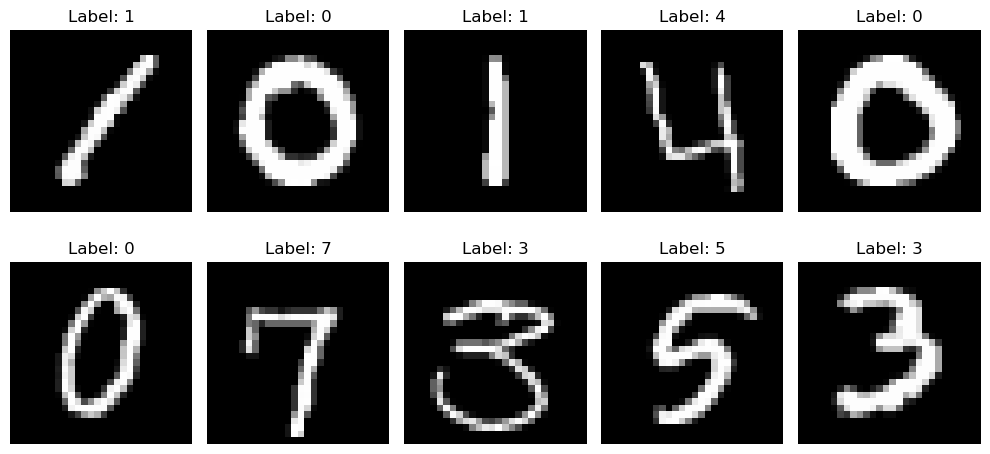

In [15]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y.iloc[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
classes = sorted(y.unique())

class_to_number = {label: i for i, label in enumerate(classes)}
number_to_class = {i: label for i, label in enumerate(classes)}

y = y.map(class_to_number).values

print("Classes:", classes)
print("Encoded Labels:", np.unique(y))

Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Encoded Labels: [0 1 2 3 4 5 6 7 8 9]


In [31]:
print("Classes:", classes)

print("First 20 encoded labels:")
print(np.argmax(y[:20], axis=1))

print("\nLabel distribution:")
print(np.sum(y, axis=0))

Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
First 20 encoded labels:
[1 0 1 4 0 0 7 3 5 3 8 9 1 3 3 1 2 0 7 5]

Label distribution:
[4132. 4684. 4177. 4351. 4072. 3795. 4137. 4401. 4063. 4188.]


In [17]:
num_classes = len(classes)

y = to_categorical(y, num_classes=num_classes)

print("Number of Classes:", num_classes)
print("Label Shape:", y.shape)

Number of Classes: 10
Label Shape: (42000, 10)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (33600, 28, 28, 1)
Testing Data: (8400, 28, 28, 1)


In [37]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(num_classes, activation="softmax")
])

model.summary()

C:\Users\DELL\.anaconda\setup\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8868 - loss: 0.3637 - val_accuracy: 0.9711 - val_loss: 0.0836
Epoch 2/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9651 - loss: 0.1191 - val_accuracy: 0.9807 - val_loss: 0.0564
Epoch 3/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9761 - loss: 0.0829 - val_accuracy: 0.9857 - val_loss: 0.0481
Epoch 4/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9796 - loss: 0.0660 - val_accuracy: 0.9780 - val_loss: 0.0738
Epoch 5/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9827 - loss: 0.0551 - val_accuracy: 0.9896 - val_loss: 0.0350
Epoch 6/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9858 - loss: 0.0468 - val_accuracy: 0.9878 - val_loss: 0.0385
Epoch 7/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9873 - loss: 0.0402 - val_accuracy: 0.9893 - val_loss: 0.0337
Epoch 8/10
473/473 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9890 - loss: 0.0360 - val_acc

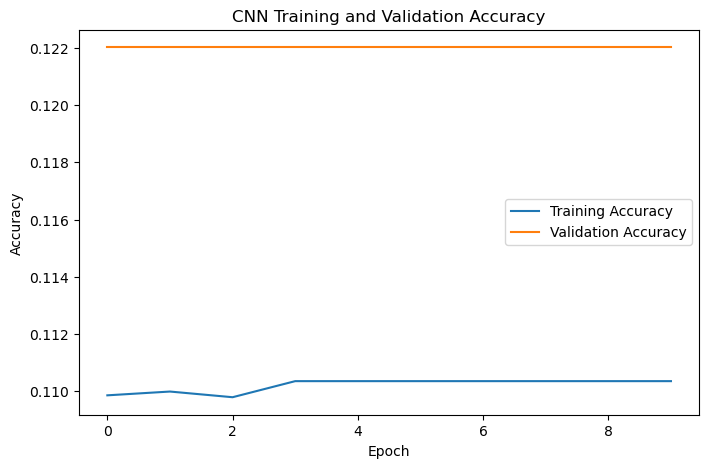

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()

plt.show()

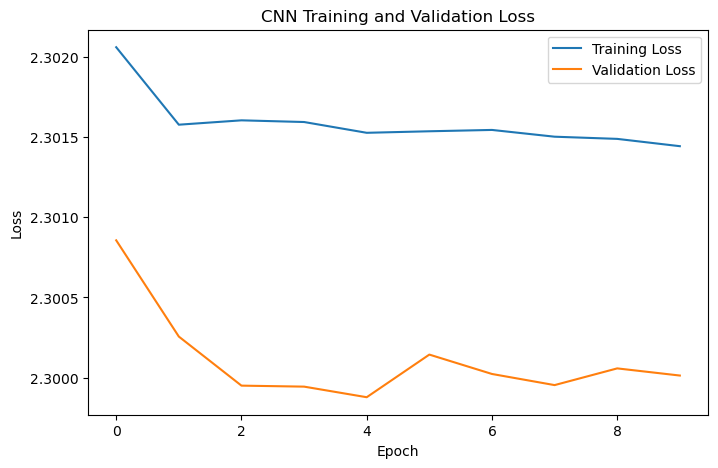

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()

plt.show()

In [41]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9901 - loss: 0.0369
Test Loss: 0.03691885992884636
Test Accuracy: 0.9901190400123596


In [42]:
predictions = model.predict(X_test)

predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(y_test, axis=1)

print("Predicted:", predicted_classes[:20])
print("Actual:", actual_classes[:20])

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Predicted: [2 5 0 6 2 1 0 3 3 0 3 7 3 0 1 7 5 2 3 5]
Actual: [2 5 0 6 2 1 0 3 3 0 3 7 3 0 1 7 5 2 3 5]


In [43]:
print(
    classification_report(
        actual_classes,
        predicted_classes,
        target_names=[str(c) for c in classes]
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       827
           1       0.99      0.99      0.99       937
           2       1.00      0.99      0.99       835
           3       0.99      0.99      0.99       870
           4       0.99      0.99      0.99       814
           5       0.98      0.99      0.98       759
           6       1.00      0.98      0.99       827
           7       0.98      0.99      0.99       880
           8       0.98      1.00      0.99       813
           9       0.99      0.98      0.99       838

    accuracy                           0.99      8400
   macro avg       0.99      0.99      0.99      8400
weighted avg       0.99      0.99      0.99      8400



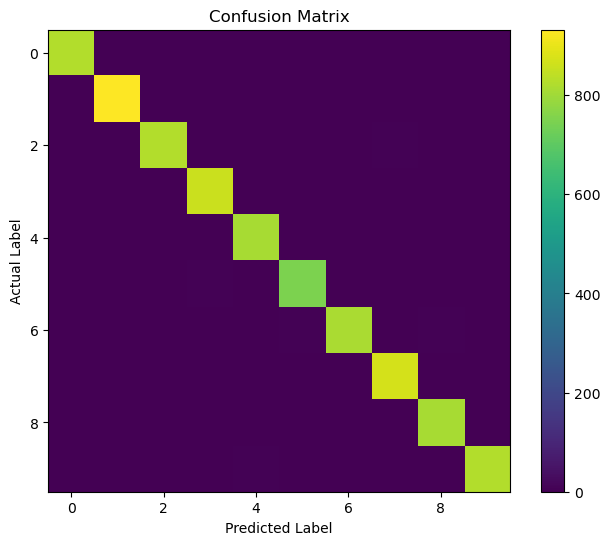

In [44]:
cm = confusion_matrix(actual_classes, predicted_classes)

plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()

plt.show()

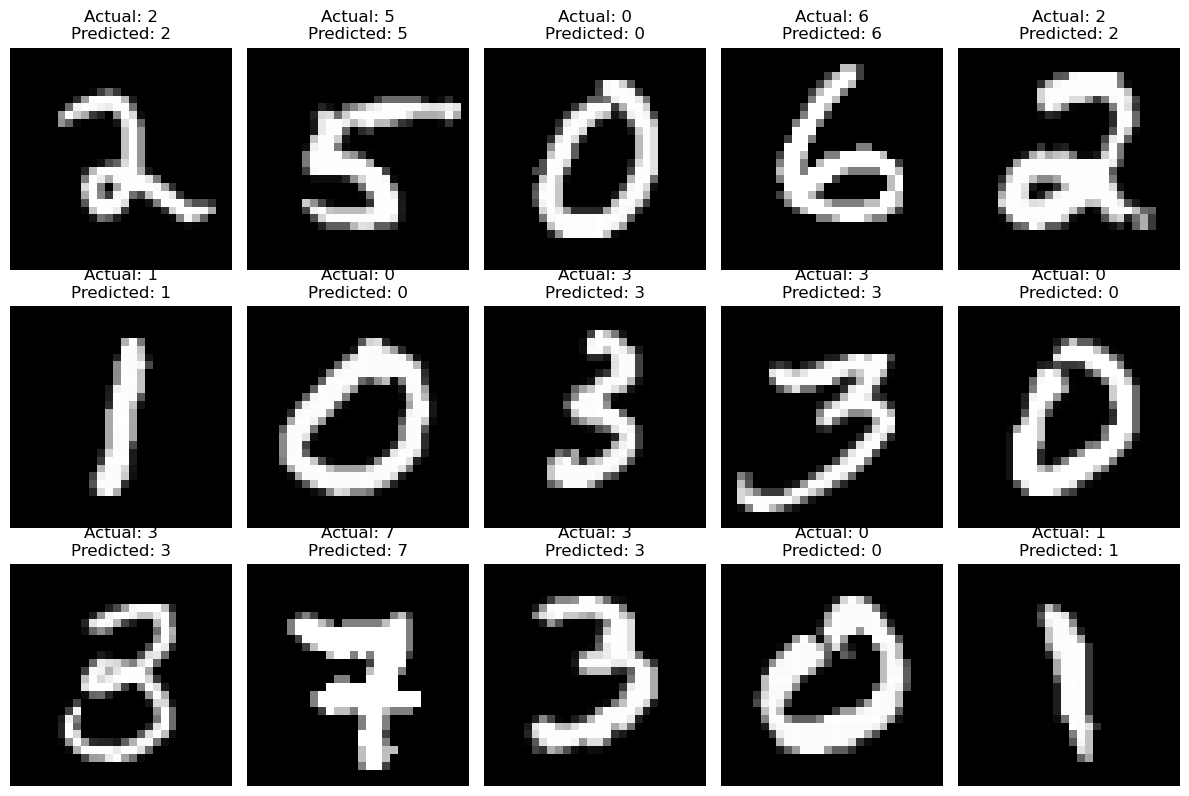

In [45]:
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")

    predicted = number_to_class[predicted_classes[i]]
    actual = number_to_class[actual_classes[i]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Predicted Character: 2
Actual Character: 2


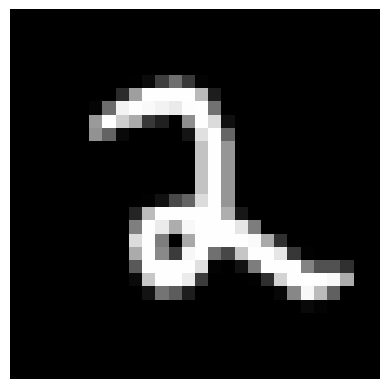

In [46]:
index = 0

image = X_test[index]

prediction = model.predict(image.reshape(1, 28, 28, 1))

predicted_class = np.argmax(prediction)

print("Predicted Character:", number_to_class[predicted_class])
print("Actual Character:", number_to_class[actual_classes[index]])

plt.imshow(image.reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()

In [47]:
model.save("handwritten_character_cnn.keras")

print("Model saved successfully.")

Model saved successfully.
